In [ ]:
%matplotlib inline
import matplotlib.pyplot as plt

In [ ]:
# Set color scheme
plt.style.use("tableau-colorblind10")

# Set ticks
plt.rc("xtick", bottom=True, top=True, direction="in")
plt.rc("ytick", left=True, right=True, direction="in")
plt.rc("xtick.minor", visible=True)
plt.rc("ytick.minor", visible=True)

In [ ]:
from np_match.debye import compute_fq
from np_match.workflow.fitting import load_experimental_data

In [2]:
from math import ceil

import numpy as np
import pandas as pd
import torch

In [ ]:
exp_data = load_experimental_data("../../../data/experimental_scattering.h5")

Disregarding key: meta


In [5]:
data_arr = np.load("../fits/fit.npz")
data = {k: v for k, v in data_arr.items()}

In [6]:
{k: v.shape for k, v in data.items()}

{'iq_int': (3655, 4, 2279),
 'xscale': (3655, 4, 92, 14),
 'yscale': (3655, 4, 92, 14),
 'biso': (3655, 4, 92, 14),
 'mse_fq': (3655, 4, 92, 14),
 'rwp_fq': (3655, 4, 92, 14),
 'family': (3655, 4, 92, 14),
 'wulff': (3655, 4, 92, 14),
 'size': (3655, 4, 92, 14),
 'max_miller': (3655, 4, 92, 14),
 'twin_111_ratio': (3655, 4, 92, 14),
 'sim_idx': (3655, 4, 92, 14),
 'fmax': (3655, 4, 92, 14),
 'exp_sample': (3655, 4, 92, 14),
 'q': (2279,),
 'q_ref': (2067,),
 'form_avg_sq': (2279,)}

In [8]:
np.setdiff1d(np.arange(3655), data["sim_idx"][:, 0, 0])

array([], dtype=int64)

In [9]:
num_sim, num_fmax, num_exp, num_biso = data["yscale"].shape

In [10]:
data["fitted_biso"] = np.concatenate(
    [
        np.zeros((num_sim, num_fmax, num_exp, num_biso - 1), dtype=bool),
        np.ones((num_sim, num_fmax, num_exp, 1), dtype=bool),
    ],
    axis=-1,
)

In [11]:
keys = set(data.keys())
keys.remove("q")
keys.remove("q_ref")
keys.remove("iq_int")
keys.remove("form_avg_sq")
data_for_pd = {k: data[k].flat for k in keys}
df = pd.DataFrame(data_for_pd)
df

,xscale,exp_sample,mse_fq,twin_111_ratio,sim_idx,fitted_biso,wulff,max_miller,size,fmax,family,rwp_fq,biso,yscale
0,1.007330,1,0.030444,NaN,0,False,True,1.0,55,0.001,oct,0.978422,0.000000,0.034483
1,1.008590,1,0.030374,NaN,0,False,True,1.0,55,0.001,oct,0.977288,0.100000,0.037849
2,1.010000,1,0.030318,NaN,0,False,True,1.0,55,0.001,oct,0.976396,0.200000,0.040896
3,1.011345,1,0.030276,NaN,0,False,True,1.0,55,0.001,oct,0.975719,0.300000,0.043620
4,1.012544,1,0.030245,NaN,0,False,True,1.0,55,0.001,oct,0.975222,0.400000,0.046037
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18830555,0.973572,92,0.042296,NaN,3654,False,False,NaN,49901,1.000,sph,0.969925,0.900000,0.020067
18830556,0.973604,92,0.042285,NaN,3654,False,False,NaN,49901,1.000,sph,0.969799,1.000000,0.021269
18830557,0.973608,92,0.042283,NaN,3654,False,False,NaN,49901,1.000,sph,0.969771,1.100000,0.022406
18830558,0.973610,92,0.042287,NaN,3654,False,False,NaN,49901,1.000,sph,0.969816,1.200000,0.023486


In [12]:
assert df["sim_idx"].unique().size == df["sim_idx"].max() + 1
assert (
    len(df)
    == (df["sim_idx"].max() + 1) * df["exp_sample"].max() * num_biso * num_fmax
)

[Text(0.5, 0, 'biso')]

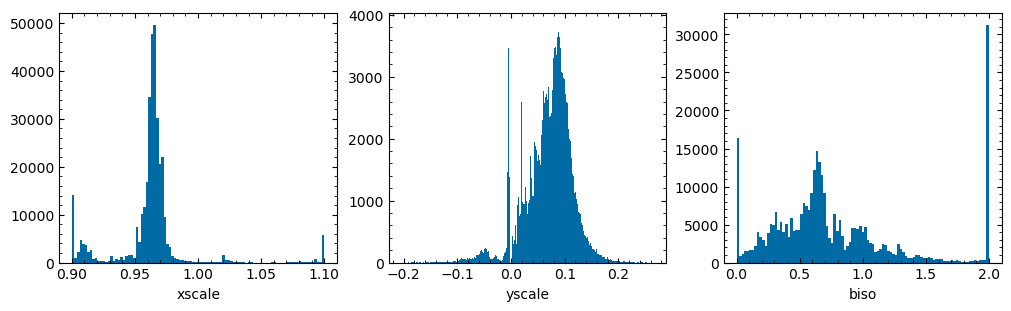

In [15]:
fig, axs = plt.subplots(1, 3, figsize=(10, 3), constrained_layout=True)
axs[0].hist(
    data["xscale"][:, -1, :, -1].flatten(),
    bins=np.linspace(0.9 - 1e-6, 1.1 + 1e-6, 100),
)
axs[0].set(xlabel="xscale")
axs[1].hist(data["yscale"][:, -1, :, -1].flatten(), bins="sqrt")
axs[1].set(xlabel="yscale")
axs[2].hist(
    data["biso"][:, -1, :, -1].flatten(),
    bins=np.linspace(0.0 - 1e-6, 2.0 + 1e-6, 100),
)
axs[2].set(xlabel="biso")

In [17]:
data["size"].max()

49990

[Text(0.5, 0, 'Number of atoms'), Text(0, 0.5, 'Counts')]

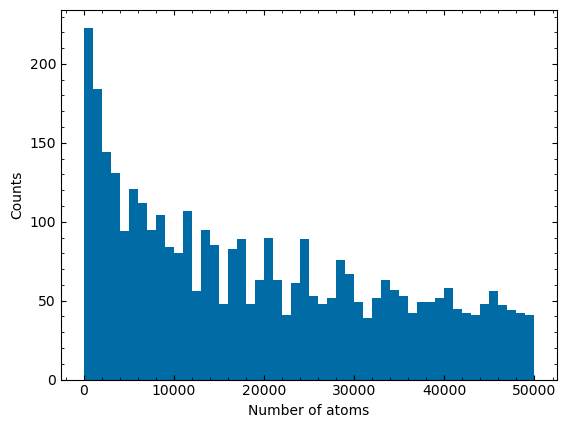

In [18]:
fig, ax = plt.subplots()
ax.hist(data["size"][:, 0, 0, 0], bins=np.arange(0, 50_001, 1000))
ax.set(xlabel="Number of atoms", ylabel="Counts")

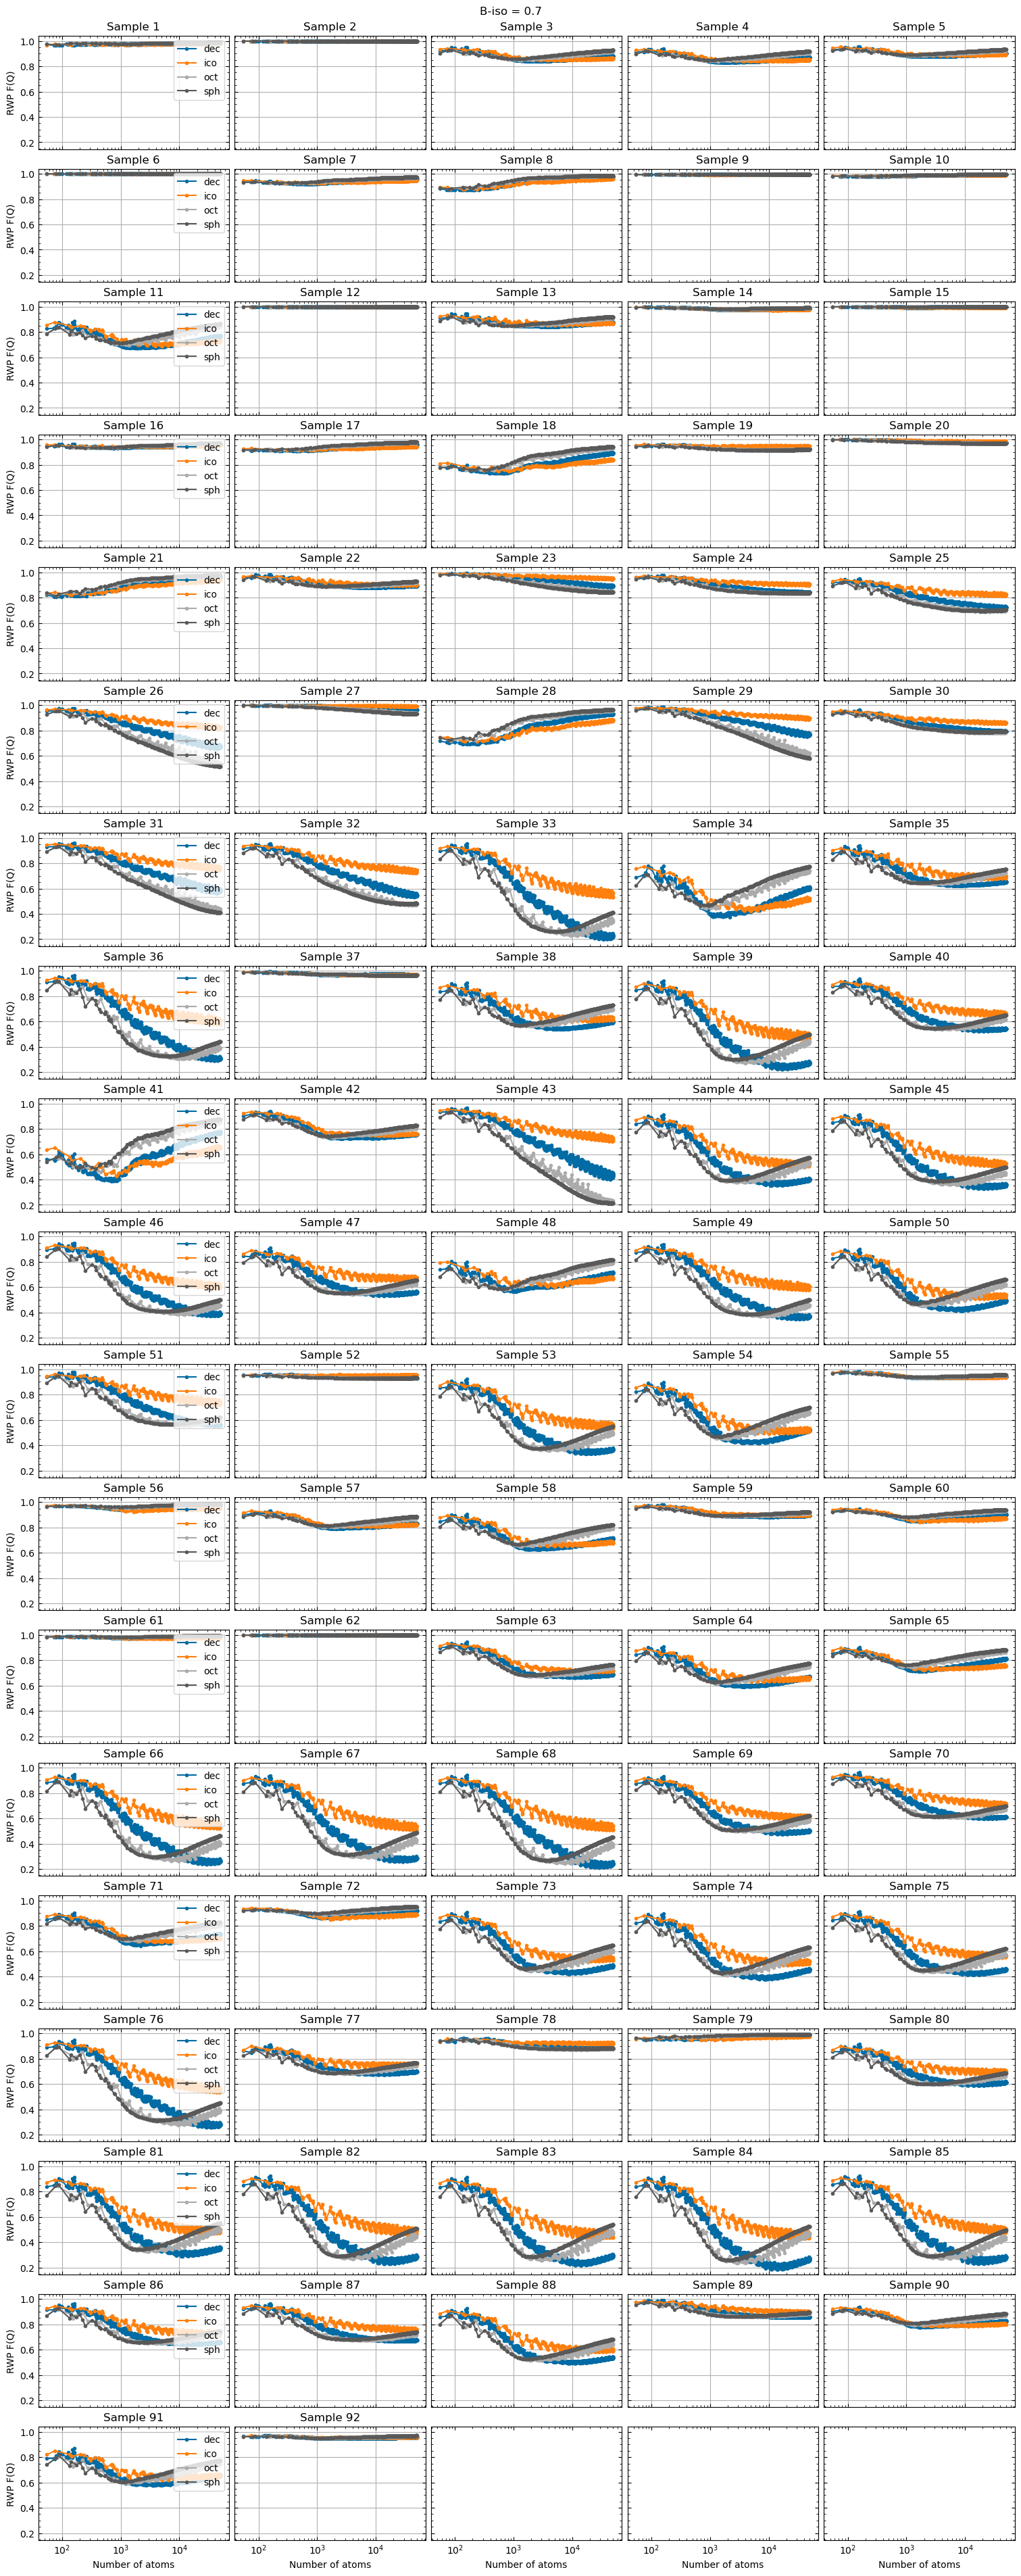

In [20]:
size = df["exp_sample"].iloc[-1]
ncols = 5
nrows = ceil(size / ncols)
fig, axs = plt.subplots(
    nrows,
    ncols,
    figsize=(3.0 * ncols, 2.0 * nrows),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)
fig.suptitle("B-iso = 0.7")
# axs[0, 0].set_yscale("log")
axs[0, 0].set_xscale("log")

for ax, (sample, group) in zip(
    axs.flat,
    df[
        ~df["fitted_biso"]
        & np.isclose(df["biso"], 0.7)
        & np.isclose(df["fmax"], 0.001)
    ].groupby("exp_sample"),
):
    ax.set_title(f"Sample {sample}")
    for fam, group_fam in group.groupby("family"):
        group_fam.sort_values("size", inplace=True)
        ax.plot(group_fam["size"], group_fam["rwp_fq"], ".-", label=fam)
        ax.grid(True)
        ax.label_outer()
        if ax in axs[:, 0]:
            ax.legend(loc="upper right")
for ax in axs[:, 0]:
    ax.set(ylabel="RWP F(Q)")
for ax in axs[-1, :]:
    ax.set(xlabel="Number of atoms")

In [ ]:
def natoms_to_diameter(natoms):
    a = 0.03034479
    return (a * natoms) ** (1 / 3)


def diameter_to_natoms(diameter):
    a = 0.03034479
    return diameter**3 / a

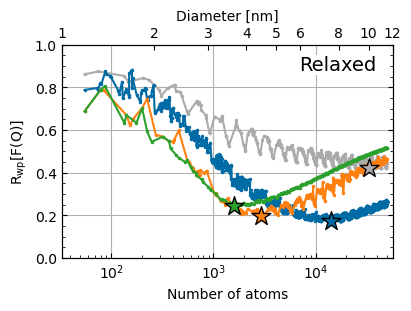

In [22]:
fig, ax = plt.subplots(
    figsize=(4, 3),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)
test_exp_sample = 84
labels = dict(
    dec="Decahedra", oct="Octahedra", ico="Icosahedra", sph="Spheres"
)
colors = dict(oct="C1", sph="tab:green", dec="C0", ico="C2")
fam_order = ["ico", "dec", "oct", "sph"]
for fam, group_fam in sorted(
    df[
        # np.isclose(df["biso"], 0.7)
        df["fitted_biso"]
        & (df.exp_sample == test_exp_sample)
        & np.isclose(df["fmax"], 0.001)
    ].groupby("family"),
    key=lambda x: fam_order.index(x[0]),
):
    group_fam.sort_values("size", inplace=True)
    ax.plot(
        group_fam["size"],
        group_fam["rwp_fq"],
        ".-",
        label=labels[fam],
        color=colors[fam],
        markersize=3,
        rasterized=True,
    )
    min_idx = group_fam.rwp_fq.idxmin()
    ax.scatter(
        group_fam["size"].loc[min_idx],
        group_fam["rwp_fq"].loc[min_idx],
        marker="*",
        color=colors[fam],
        edgecolor="k",
        s=200,
        zorder=5,
    )
ax.grid(True)
ax.minorticks_on()
# ax.grid(True, which="minor", axis="y")
ax.tick_params(axis="y", which="minor", right=True)
# ax.legend(loc="lower left")
ax.set(
    xlabel="Number of atoms",
    ylabel="$\\mathrm{R_{wp} \\left[F(Q)\\right]}$",
    xscale="log",
    # yscale="log",
    xlim=(30, 60_000),
    ylim=(0, 1),
)

ax.text(
    0.95,
    0.95,
    "Relaxed",
    fontdict=dict(fontsize=14),
    transform=ax.transAxes,
    ha="right",
    va="top",
    bbox=dict(facecolor="white", edgecolor="none", pad=0.5, alpha=1.0),
)

diameters = [1, 2, 3, 4, 5, 6, 8, 10, 12]
natoms = [diameter_to_natoms(d) for d in diameters]
xlim = (natoms[0], natoms[-1])
ax.set_xlim(xlim)
twiny = ax.twiny()
twiny.set(xlabel="Diameter [nm]", xscale="log", xlim=xlim)

twiny.set_xticks(natoms, diameters)
twiny.tick_params(axis="x", which="minor", top=False)

In [23]:
fig.savefig("rwp_size_sample_84_relax_free_biso.pdf", dpi=300)

In [21]:
fit_keys = ["xscale", "yscale", "biso"]

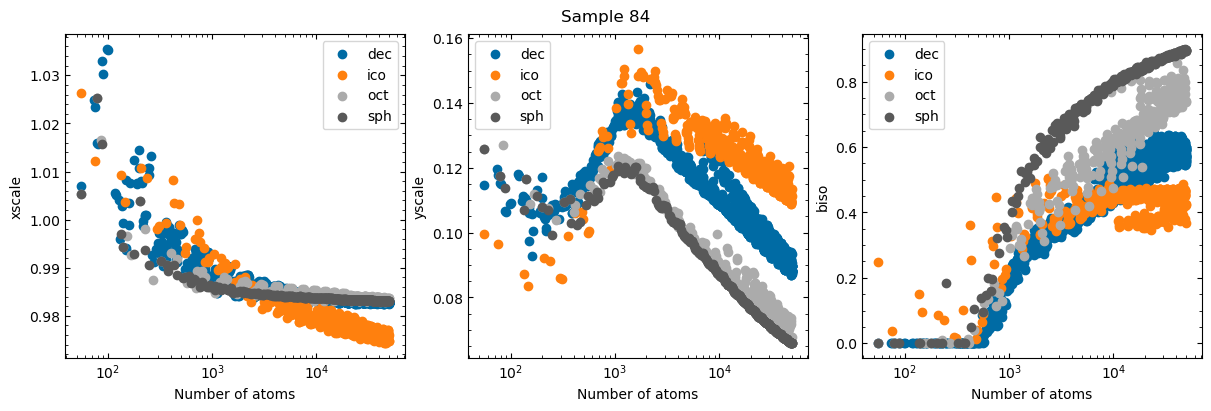

In [25]:
# B-iso vs number of atoms
fig, axs = plt.subplots(1, 3, figsize=(12, 4), constrained_layout=True)
fig.suptitle(f"Sample {test_exp_sample}")
for fam, group in df[
    df["fitted_biso"]
    # & np.isclose(df["biso"], 0.7)
    & (df.exp_sample == test_exp_sample)
    & np.isclose(df["fmax"], 0.001)
].groupby("family"):
    for k, ax in zip(fit_keys, axs):
        if k == "biso":
            xmask = group["size"]
        ax.scatter(group["size"], group[k], label=fam)
        ax.set(xlabel="Number of atoms", ylabel=k, xscale="log")
        ax.legend()

In [56]:
assert np.allclose(data["q_ref"], exp_data[test_exp_sample - 1].q)

wulff                 True
max_miller             2.0
sim_idx               1282
family                 dec
biso                   0.7
fmax                 0.001
exp_sample              84
fitted_biso          False
mse_fq            0.001183
twin_111_ratio         0.5
yscale            0.125206
size                 11407
rwp_fq            0.185147
xscale            0.983218
Name: 6606033, dtype: object

wulff                 True
max_miller             1.0
sim_idx                247
family                 ico
biso                   0.7
fmax                 0.001
exp_sample              84
fitted_biso          False
mse_fq            0.006431
twin_111_ratio        0.25
yscale            0.126356
size                 33069
rwp_fq            0.431683
xscale            0.977945
Name: 1273713, dtype: object

wulff                 True
max_miller             3.0
sim_idx               1548
family                 oct
biso                   0.7
fmax                 0.001
exp_sample            

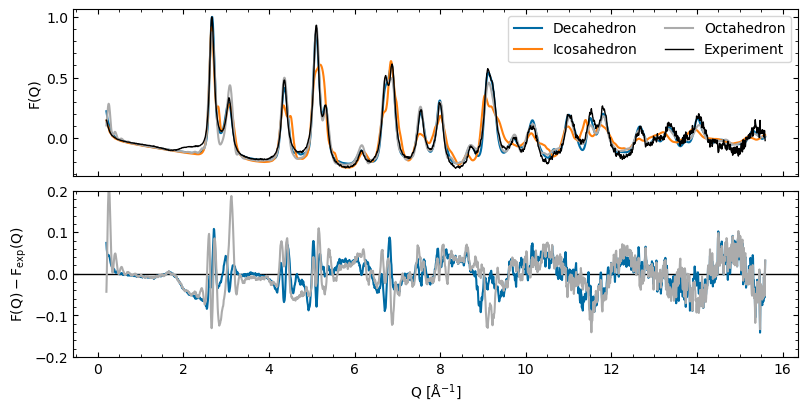

In [ ]:
fig, (ax, ax_res) = plt.subplots(
    2, 1, figsize=(8, 4), constrained_layout=True, sharex=True
)
for fam, group in df[
    np.isclose(df["biso"], 0.7)
    & (df.exp_sample == test_exp_sample)
    & np.isclose(df["fmax"], 0.001)
].groupby("family"):
    if fam in ("sph",):
        continue
    row_idx = group.mse_fq.idxmin()
    row = df.iloc[row_idx]
    print(row)
    print()
    y = (
        row.yscale
        * compute_fq(
            form_avg_sq=torch.from_numpy(data["form_avg_sq"]),
            size=row["size"],
            q=torch.from_numpy(data["q"]),
            iq_int=torch.from_numpy(data["iq_int"][row.sim_idx, 0]),
            biso=row.biso,
            qdamp=0.023,
            xscale=row.xscale,
            q_ref=torch.from_numpy(data["q_ref"]),
        )[0].numpy()
    )
    line = ax.plot(
        data["q_ref"],
        y,
        label=f"{labels[fam].replace('dra', 'dron')}",
    )[0]
    if fam != "ico" and fam != "sph":
        ax_res.plot(
            data["q_ref"],
            y - exp_data[test_exp_sample - 1].fq,
            color=line.get_color(),
        )

ax.plot(
    exp_data[test_exp_sample - 1].q,
    exp_data[test_exp_sample - 1].fq,
    label="Experiment",
    color="k",
    lw=1.0,
)
ax.set(ylabel="F(Q)")
ax_res.set(
    xlabel=r"Q [$\mathrm{Å^{-1}}$]",
    ylabel=r"$\mathrm{F(Q) - F_{exp}(Q)}$",
    ylim=(-0.2, 0.2),
)
ax_res.axhline(0, color="k", lw=1.0, zorder=0)
ax.legend(loc="upper right", ncols=2)

In [62]:
fig.savefig("sample_84_best_nps.png", dpi=300)